
$\hat{y}_1=f_1(X)$

$\hat{x}=f_2(X,\hat{y}_1)$

$\hat{y}=f_3(X,\hat{y}_1,\hat{x})$

$\hat{r}=f_4(X,\hat{y}_1,\hat{x},\hat{y})$

In [340]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import KFold, cross_val_predict
from xgboost import XGBRegressor

df = pd.read_csv('databasev4_2.csv')

# cp = pd.read_csv('databasev5_presenca.csv')

# df = df[cp['classe']==2]
# df = df[(df['pos_x']>0.08) & (df['pos_x']<0.2)].reset_index(drop=True)
# df = df[df['presence']==1]
# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# df = df.drop(columns=na)

In [341]:
def print_results(reg:bool,y_test,y_pred):
    if reg == True:
        print('R²:', r2_score(y_test, y_pred))
        print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
        print('MAE:', mean_absolute_error(y_test, y_pred))
    else:
        print("Acurácia:", accuracy_score(y_test,y_pred))
        print("\nMatriz de confusão:\n",confusion_matrix(y_test,y_pred))
        print("\nRelatório:\n",classification_report(y_test,y_pred))

Models

In [342]:
cv = KFold(n_splits=10,shuffle=False)

hgb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=100, max_leaf_nodes=31,
                                     max_depth=None, min_samples_leaf=20, l2_regularization=0.0, random_state=42 )

model_hgb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=2000, max_leaf_nodes=31,
                                          early_stopping=True, validation_fraction=0.15, n_iter_no_change=50,random_state=42)

model_xg = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)

Detecção da presença do cilindro via Gradient Boosting Classifier

In [343]:
X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
Y = df['presence']

y1 = cross_val_predict(hgb, X, Y,cv=cv, method='predict')
y1 = pd.DataFrame(y1).rename(columns={0:'presence_pred'})

print_results(reg=False,y_test=Y,y_pred=y1)

Acurácia: 0.9316

Matriz de confusão:
 [[1024  194]
 [ 148 3634]]

Relatório:
               precision    recall  f1-score   support

           0       0.87      0.84      0.86      1218
           1       0.95      0.96      0.96      3782

    accuracy                           0.93      5000
   macro avg       0.91      0.90      0.91      5000
weighted avg       0.93      0.93      0.93      5000



Predição da posição lateral via Gradient Boosting Regressor

In [344]:
X2 = X[y1['presence_pred']==1]
Y2 = df['pos_x'][y1['presence_pred']==1]

y2 = cross_val_predict(model_hgb, X2, Y2,cv=cv, method='predict')
y2 = pd.DataFrame(y2)
y2 = y2.rename(columns={0:'pos_x_pred'})

print('Posição em x:')
print_results(reg=True,y_test=Y2,y_pred=y2)

Posição em x:
R²: 0.8999187927499384
RMSE: 0.013743877121160082
MAE: 0.009057091987475313


Predição da posição vertical via XGBoost

In [345]:
X3 = pd.concat((X2.reset_index(drop=True),y2),axis=1)
Y3 = df['pos_y'][y1['presence_pred']==1]

y3 = cross_val_predict(model_hgb, X3, Y3,cv=cv, method='predict')
y3 = pd.DataFrame(y3).rename(columns={0:'pos_y_pred'})

print_results(reg=True,y_test=Y3,y_pred=y3)

R²: 0.8331849507290046
RMSE: 0.006169638429930306
MAE: 0.0048693767437720985


Predição do raio via XGBoost

In [346]:
X4 = pd.concat((X3,y3),axis=1)
Y4 = df['radius'][y1['presence_pred']==1]

y4 = cross_val_predict(model_hgb, X4, Y4,cv=cv, method='predict')
y4 = pd.DataFrame(y4)
y4 = y4.rename(columns={0:'radius_pred'})

print('Raio:')
print_results(reg=True,y_test=Y4,y_pred=y4)

Raio:
R²: 0.20554413673685812
RMSE: 0.0037808751561986104
MAE: 0.003157266083257942


In [347]:
predictions = pd.concat((y2,y3,y4),axis=1)
display(predictions)

display(df[['pos_x','pos_y','radius']][y1['presence_pred']==1].reset_index(drop=True))

,pos_x_pred,pos_y_pred,radius_pred
0,0.160682,0.089281,0.014294
1,0.106898,0.125655,0.014224
2,0.187389,0.115389,0.014823
3,0.203462,0.089949,0.015648
4,0.161034,0.095359,0.010516
...,...,...,...
3823,0.189981,0.090452,0.010936
3824,0.157952,0.088811,0.017590
3825,0.091190,0.083907,0.008543
3826,0.109955,0.086800,0.013198


,pos_x,pos_y,radius
0,0.162632,0.093158,0.019263
1,0.105789,0.127368,0.014842
2,0.191053,0.124737,0.008947
3,0.210000,0.080000,0.014105
4,0.172105,0.090526,0.014105
...,...,...,...
3823,0.181579,0.082632,0.013368
3824,0.162632,0.090526,0.016316
3825,0.077368,0.080000,0.007474
3826,0.115263,0.093158,0.008211


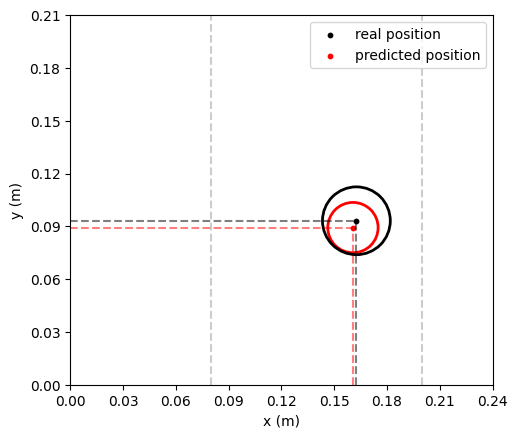

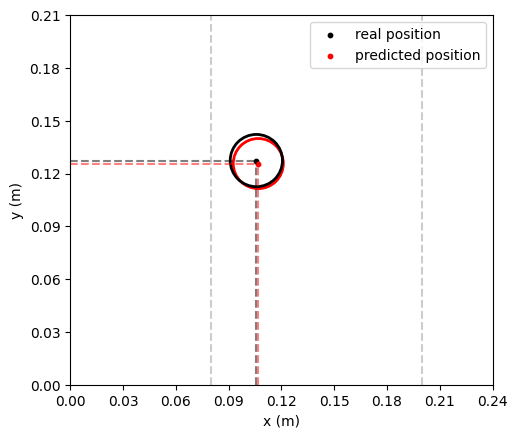

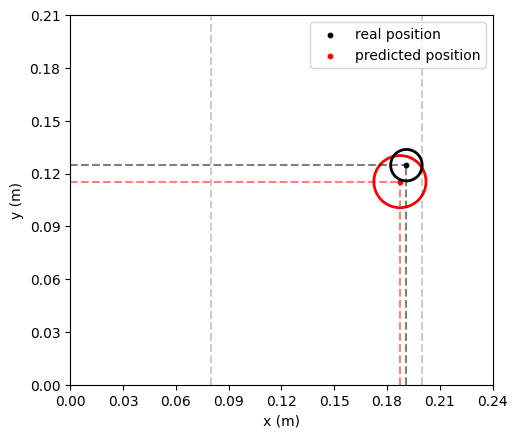

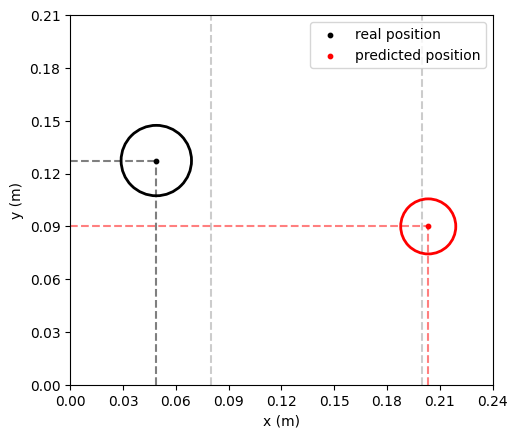

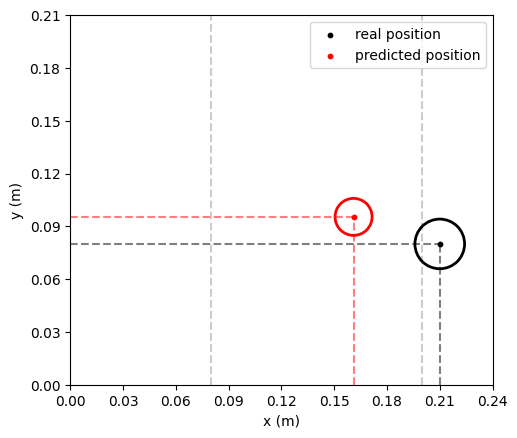

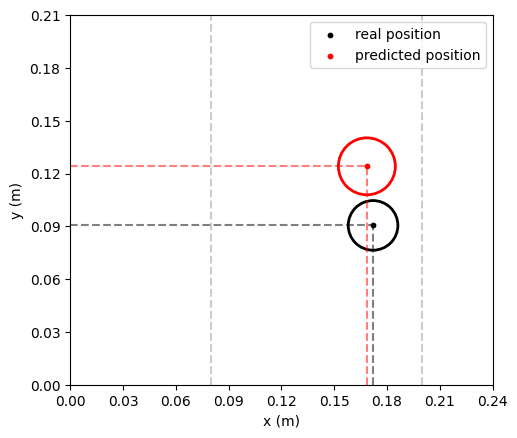

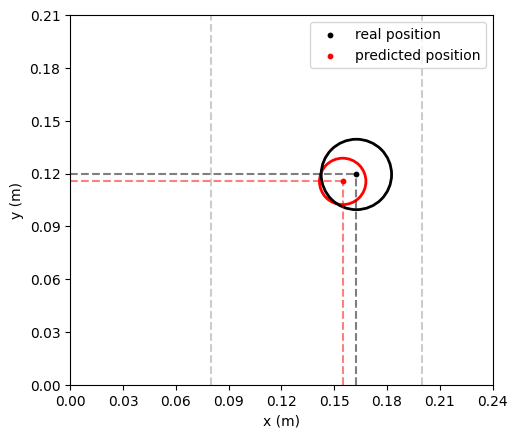

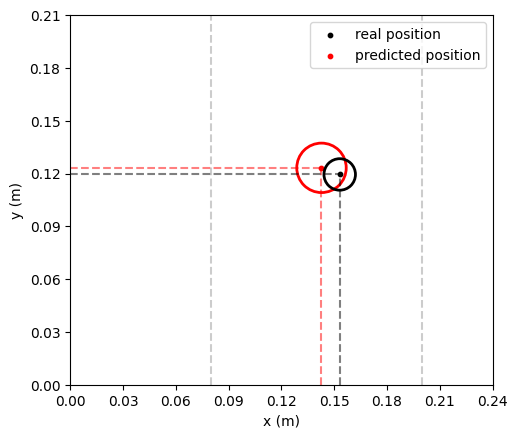

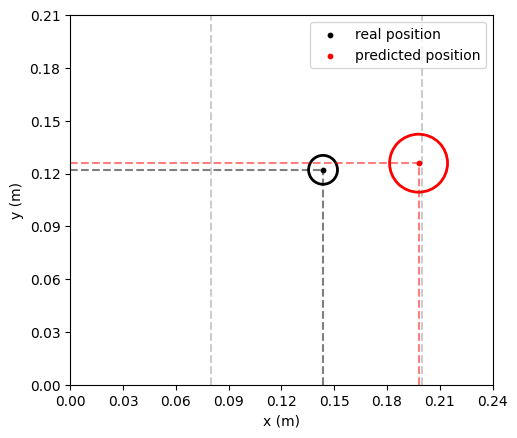

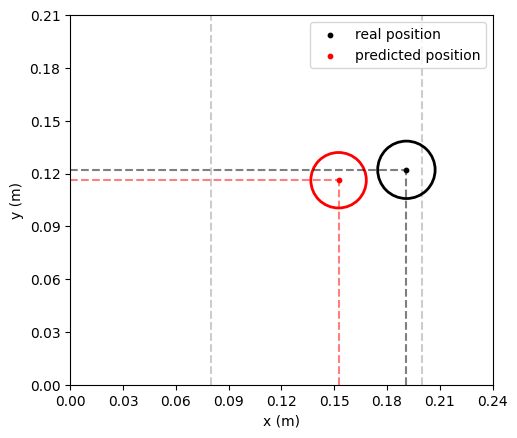

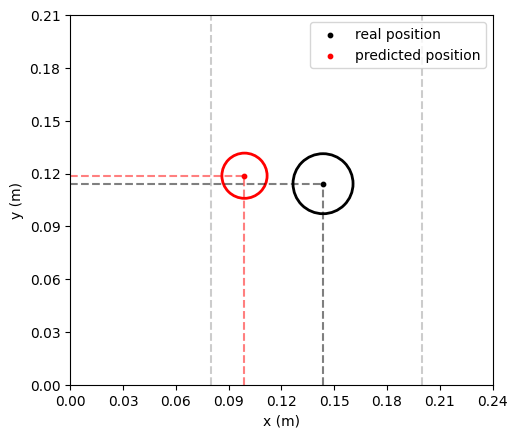

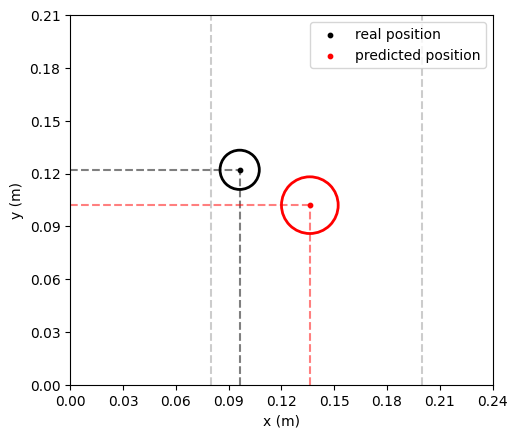

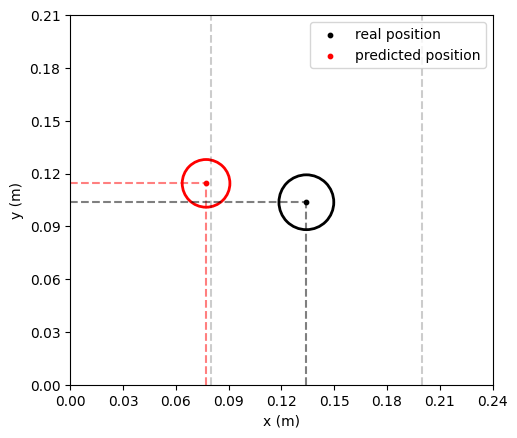

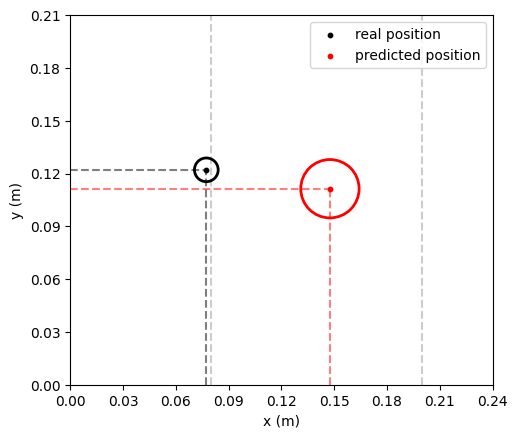

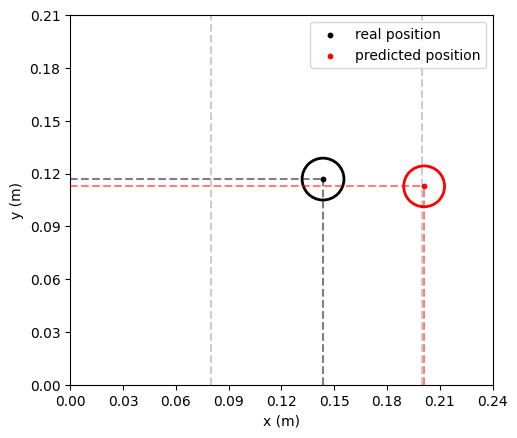

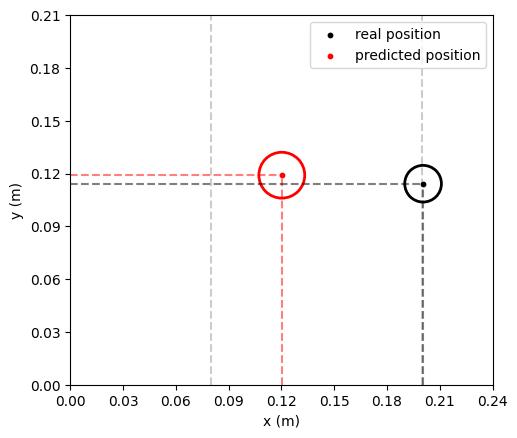

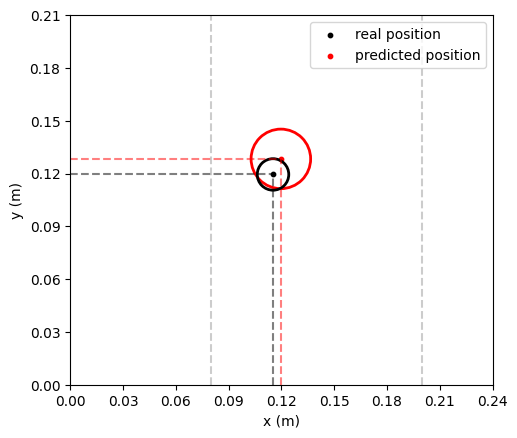

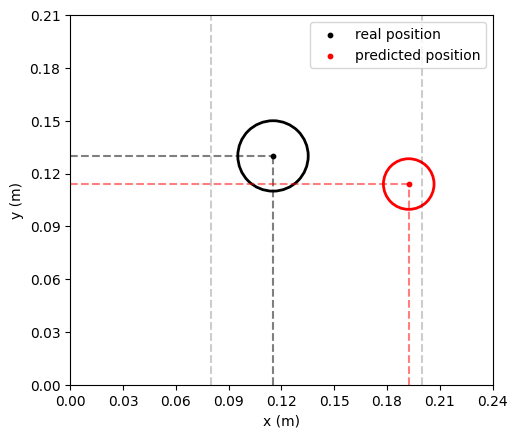

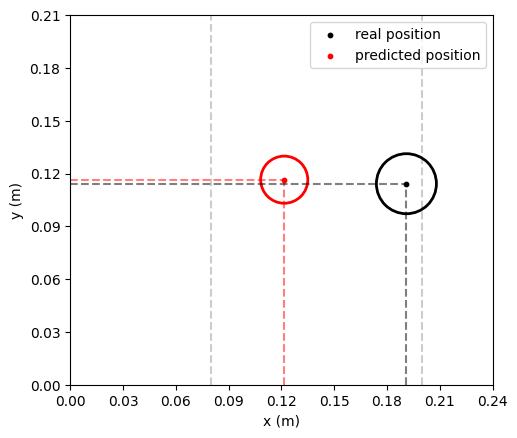

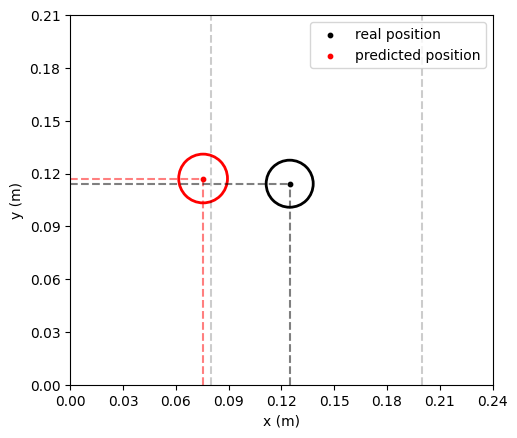

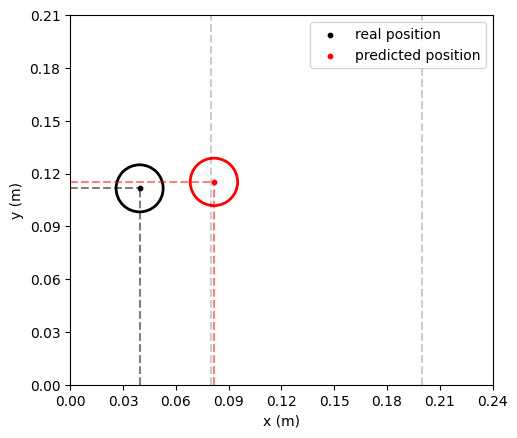

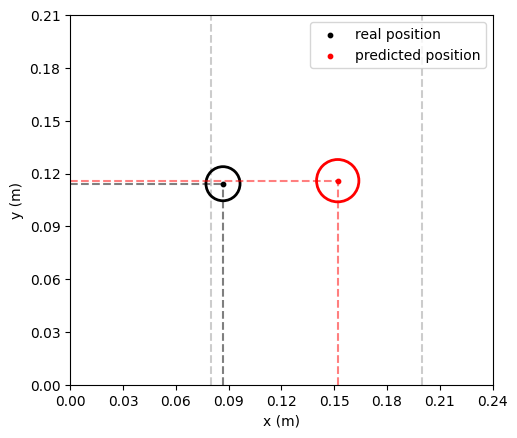

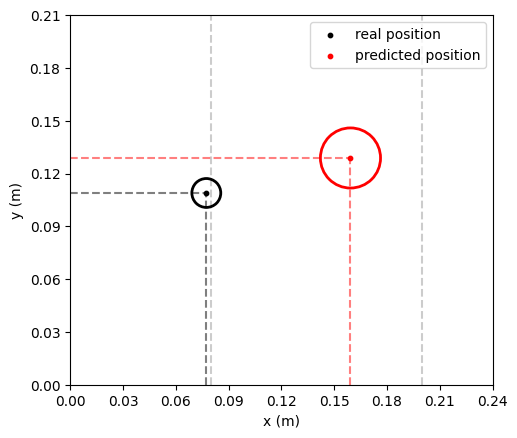

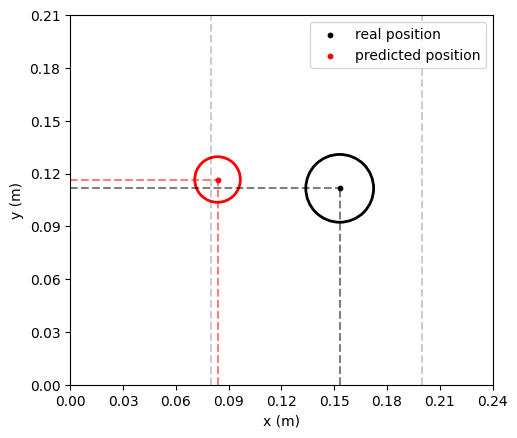

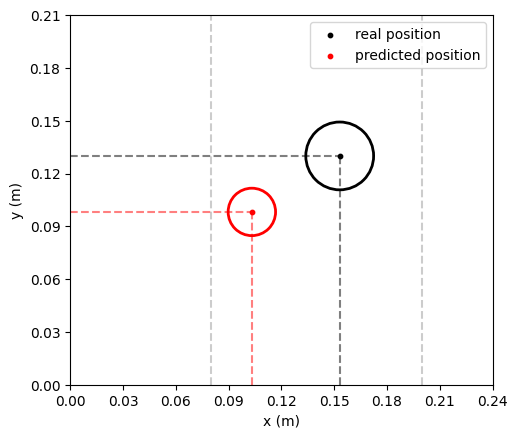

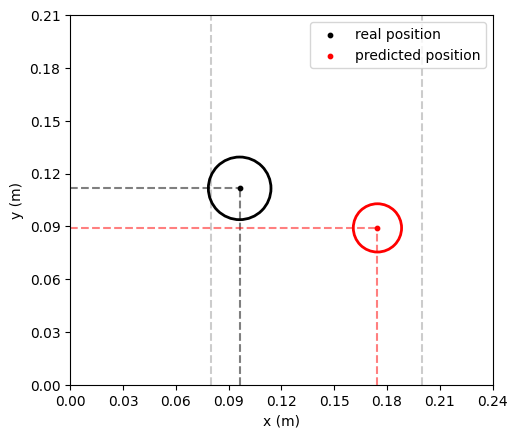

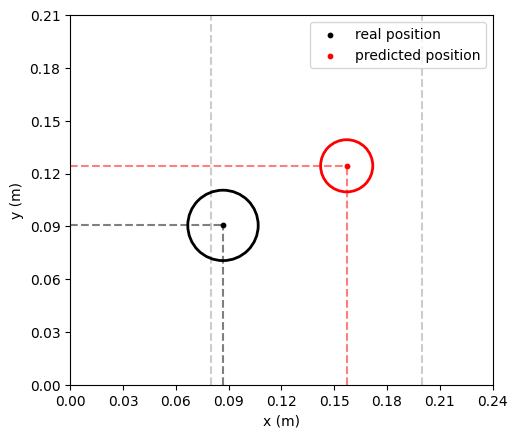

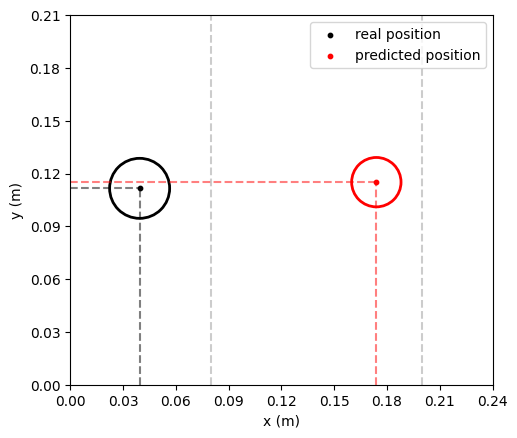

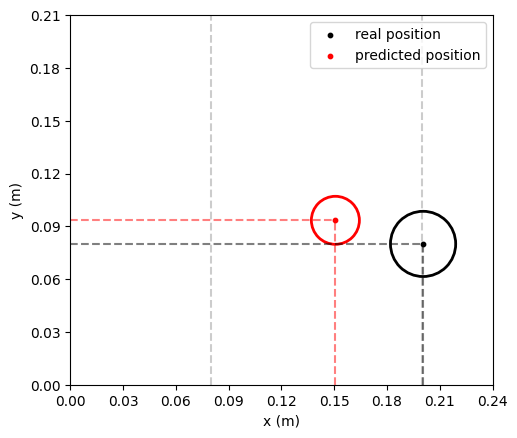

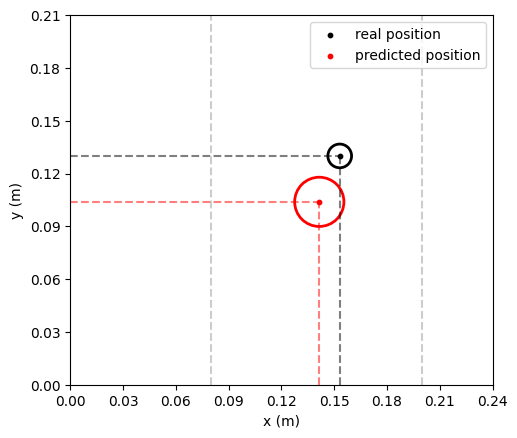

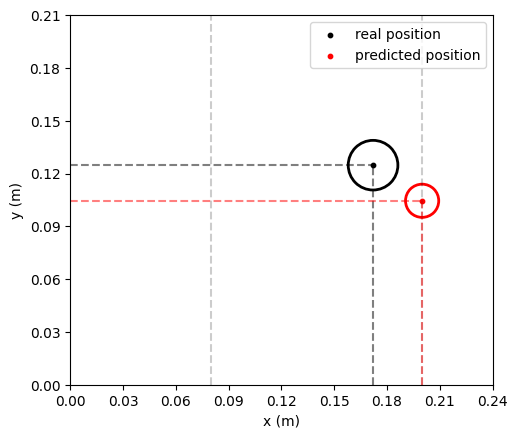

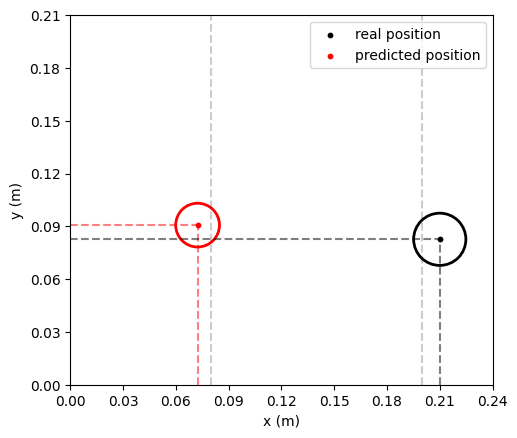

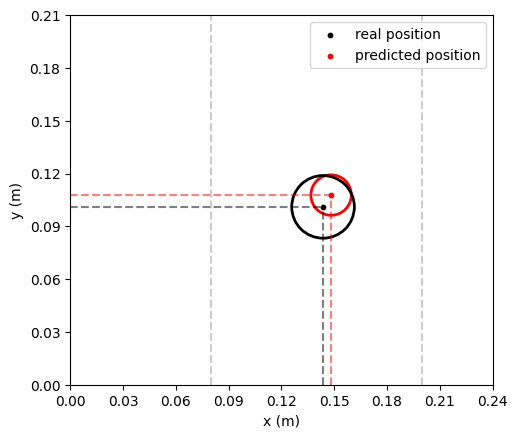

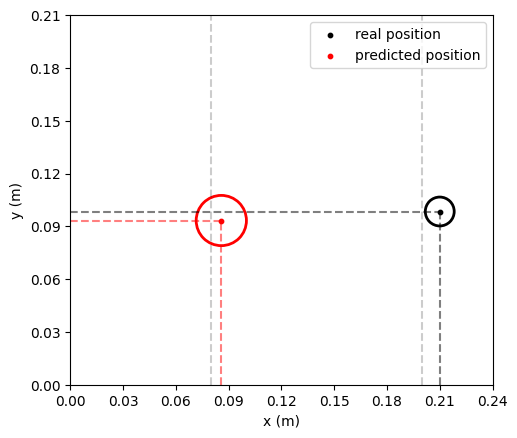

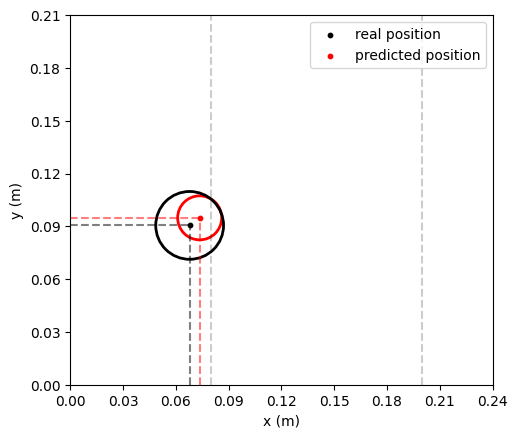

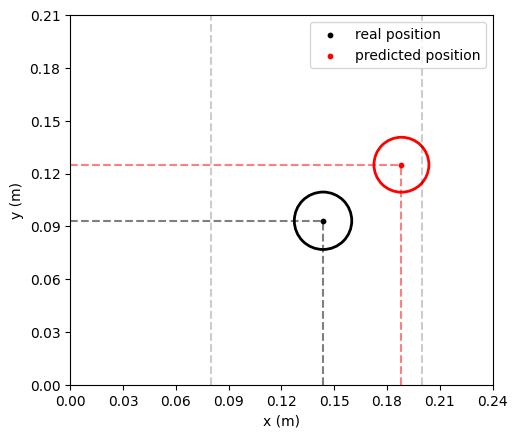

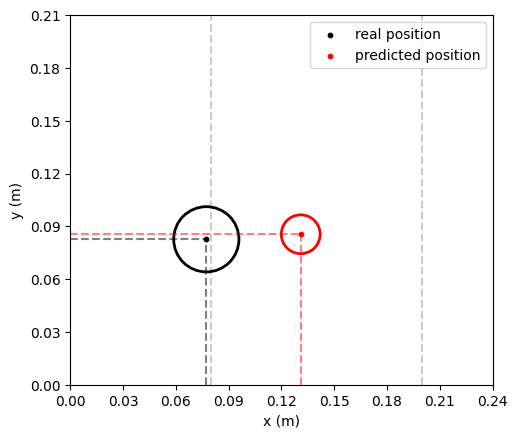

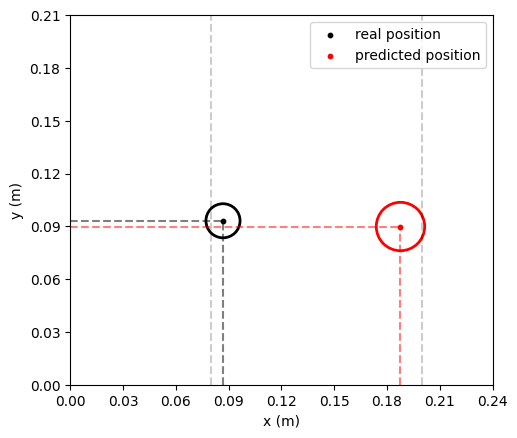

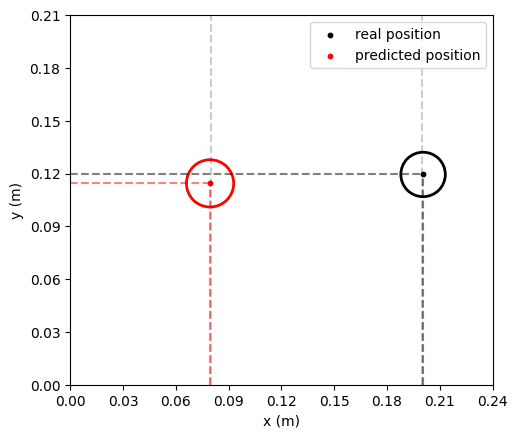

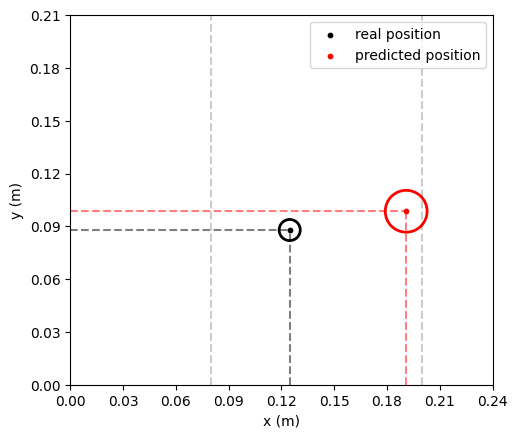

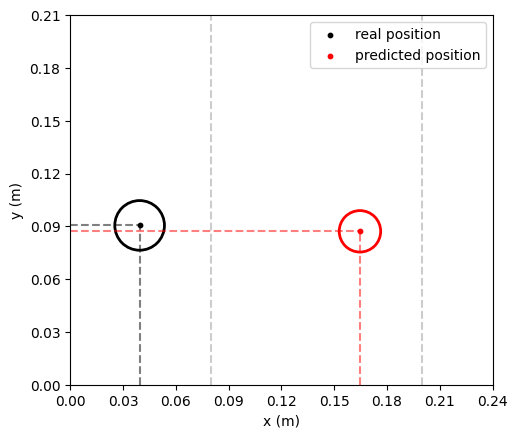

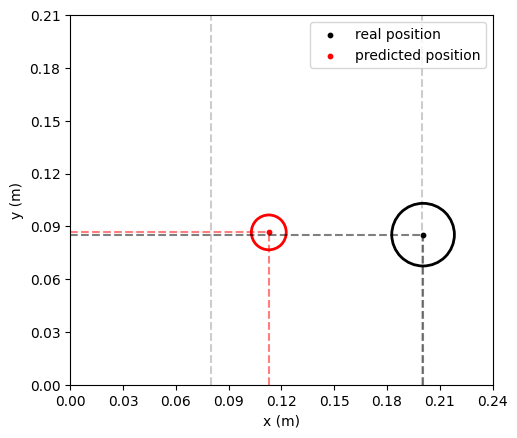

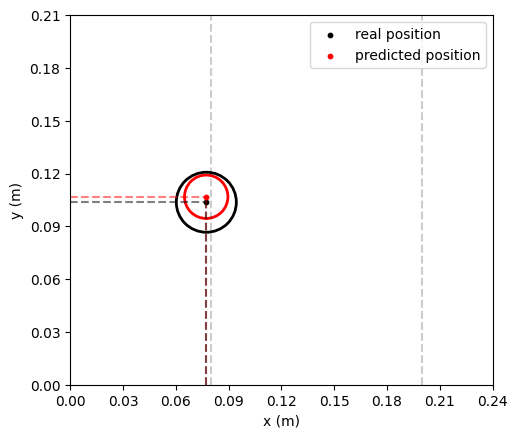

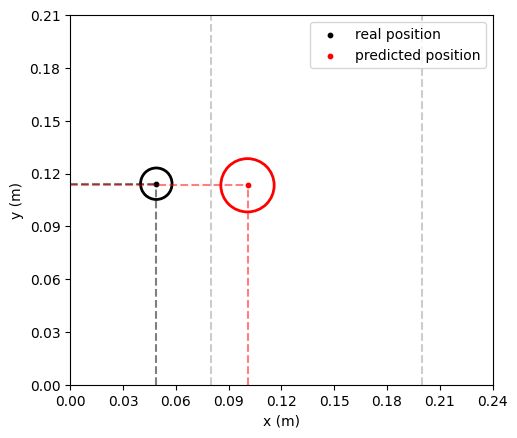

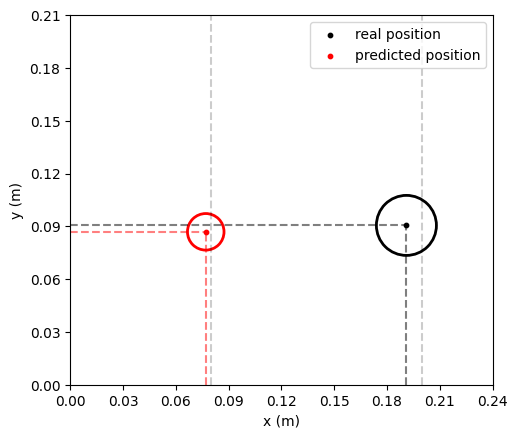

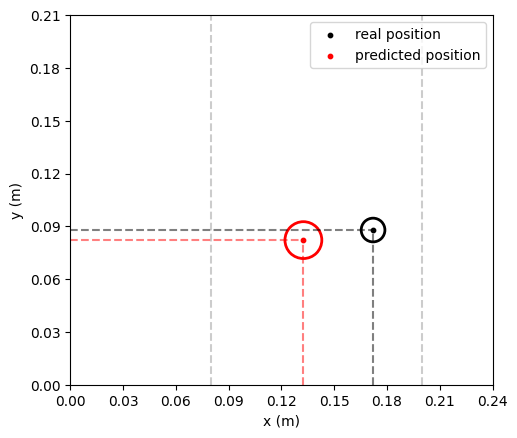

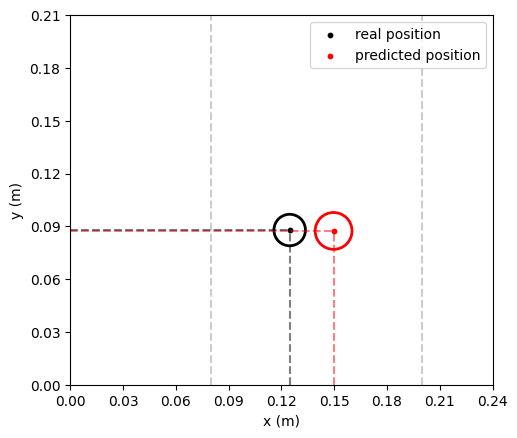

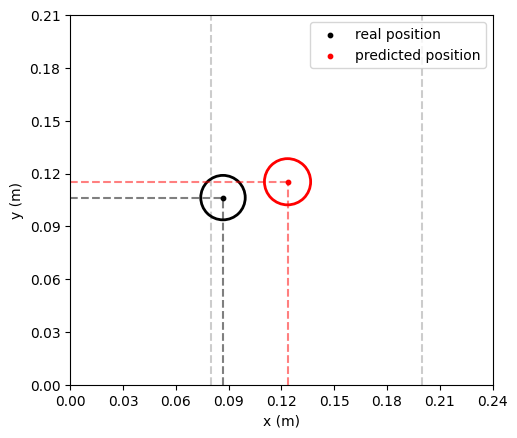

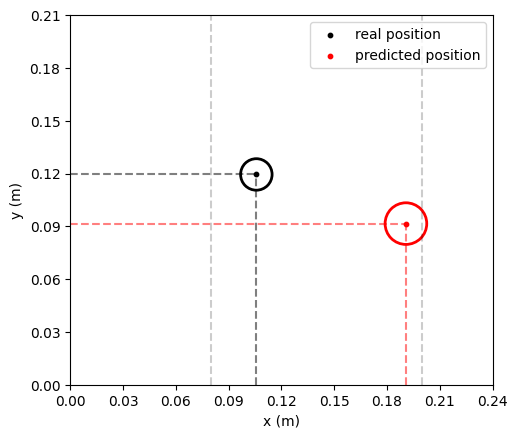

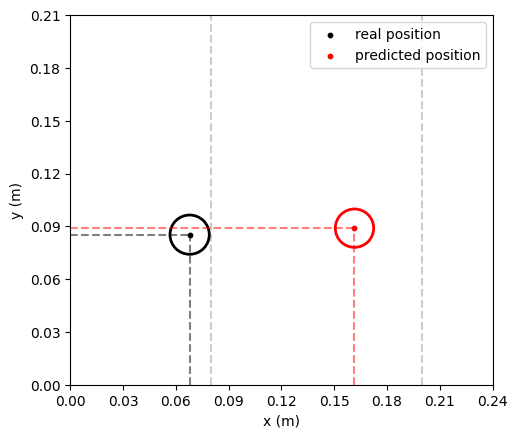

In [348]:
pos_x_pred = predictions['pos_x_pred']
pos_y_pred = predictions['pos_y_pred']
radius_pred = predictions['radius_pred']

df = df.reset_index()
pos_x = df['pos_x']
pos_y = df['pos_y']
radius = df['radius']


for i in range(50):
    fig, ax = plt.subplots()

    # Círculo: centro (x,y) e raio r
    circulo_real = plt.Circle((pos_x[i], pos_y[i]), radius[i], color='black', fill=False, linewidth=2)
    plt.scatter(pos_x[i], pos_y[i],color='black',s=10,label='real position')

    circulo_pred = plt.Circle((pos_x_pred[i], pos_y_pred[i]), radius_pred[i], color='red', fill=False, linewidth=2)
    plt.scatter(pos_x_pred[i], pos_y_pred[i],color='red',s=10,label='predicted position')

    ax.add_patch(circulo_pred)
    ax.add_patch(circulo_real)
    ax.set_xlim(0, 0.24)
    ax.set_ylim(0, 0.21)
    ax.set_aspect('equal')
    ax.set_xticks(np.arange(0,0.241,0.03))
    ax.set_yticks(np.arange(0,0.211,0.03))
    ax.set_xlabel(r"x (m)")
    ax.set_ylabel(r"y (m)")
    ax.axvline(x=0.08,color='black',ls='--',alpha=0.2)
    ax.axvline(x=0.2,color='black',ls='--',alpha=0.2)

    ax.axvline(x=pos_x_pred[i],color='red',ls='--',alpha=0.5,ymax=pos_y_pred[i]/0.21)
    ax.axvline(x=pos_x[i],color='black',ls='--',alpha=0.5,ymax=pos_y[i]/0.21)
    ax.axhline(y=pos_y_pred[i],color='red',ls='--',alpha=0.5,xmax=pos_x_pred[i]/0.24)
    ax.axhline(y=pos_y[i],color='black',ls='--',alpha=0.5,xmax=pos_x[i]/0.24)


    ax.legend()
    plt.show()